# Vélib' Métropole : une station sera-t-elle vide dans 30 minutes ?

**DATA-IA-EXE710 · Télécom Paris · Kit Data Science**

Cette analyse exploite les relevés réels du **25 au 30 octobre 2026**, période où la collecte était régulière. La période est fixée dans le code pour que les résultats restent reproductibles, même si le dépôt reçoit de nouveaux instantanés. Les graphiques et tableaux ci-dessous proviennent d'une exécution complète depuis un environnement propre.

**Question étudiée (sur les stations ouvertes aux deux instants) :** une station en service à l'instant *t* sera-t-elle vide exactement à *t* + 30 minutes ?

**Plan :** chargement ; couverture ; qualité ; exploration ; géographie ; construction de la cible et des variables ; modèles et baselines ; limites.

Une station est en service si `is_renting == 1`. La cible vaut 1 si elle est en service à *t* et à *t* + 30 minutes, et si `num_bikes_available == 0` à *t* + 30 minutes. Les créneaux sans observation future à l'horizon exact sont exclus. Ce notebook unique réunit la qualité, l'exploration, la géographie, la construction des variables, la modélisation et la conclusion sur une seule cible.


## 1. Chargement des données

In [1]:
# Récupérer le dépôt GitHub (dans Colab) ou utiliser le dossier local.
import importlib.util
import os
import subprocess
import sys

if os.path.exists("../data/raw"):           # notebook lancé depuis le dossier notebooks/
    DOSSIER = ".."
elif os.path.exists("data/raw"):            # notebook lancé depuis la racine du dépôt
    DOSSIER = "."
else:                                       # Colab : on clone le dépôt
    if not os.path.exists("velib-kit-data-science"):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "finalisation-remise-2026-11-08",
                        "https://github.com/G-Akram01/velib-kit-data-science.git"], check=True)
    DOSSIER = "velib-kit-data-science"

print("Dossier du projet :", DOSSIER)

# Folium est la seule dépendance supplémentaire nécessaire pour la carte interactive.
# Dans Colab propre, l'installer si elle n'est pas déjà disponible.
if importlib.util.find_spec("folium") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "folium==0.20.0"], check=True)


Dossier du projet : .


In [2]:
import glob
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Les heures de collecte sont en UTC ; on les convertit en heure de Paris pour les graphiques.
plt.rcParams["date.autoformatter.hour"] = "%d/%m %Hh"
plt.rcParams["date.autoformatter.day"] = "%d/%m"
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLEU = "#2a78d6"
ORANGE = "#eb6834"
GRIS = "#8a8984"

In [3]:
def lire_json_gz(chemin):
    with gzip.open(chemin, "rt", encoding="utf-8") as f:
        return json.load(f)


def nb_velos_type(liste_types, type_velo):
    """Extrait le nombre de vélos 'mechanical' ou 'ebike' de num_bikes_available_types."""
    if not isinstance(liste_types, list):
        return np.nan
    for element in liste_types:
        if type_velo in element:
            return element[type_velo]
    return np.nan


fichiers = sorted(glob.glob(f"{DOSSIER}/data/raw/*/*.json.gz"))
print("Nombre de fichiers :", len(fichiers))

morceaux = []
for chemin in fichiers:
    contenu = lire_json_gz(chemin)
    stations = pd.DataFrame(contenu["stations"])
    stations["collecte"] = contenu["collected_at_utc"]
    morceaux.append(stations)

df = pd.concat(morceaux, ignore_index=True)
print("Dimensions :", df.shape)
df.head()

Nombre de fichiers : 2088


Dimensions : (3172711, 13)


,station_id,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode,station_opening_hours,collecte
0,213688169,2,2,"[{'mechanical': 1}, {'ebike': 1}]",33,33,1,1,1,1792861665,16107,None,2026-10-24T17:55:14+00:00
1,19179944124,26,26,"[{'mechanical': 24}, {'ebike': 2}]",1,1,1,1,1,1792861861,40001,None,2026-10-24T17:55:14+00:00
2,18795078746,2,2,"[{'mechanical': 1}, {'ebike': 1}]",26,26,1,1,1,1792861540,32304,None,2026-10-24T17:55:14+00:00
3,36255,3,3,"[{'mechanical': 0}, {'ebike': 3}]",18,18,1,1,1,1792862027,9020,None,2026-10-24T17:55:14+00:00
4,251039991,5,5,"[{'mechanical': 1}, {'ebike': 4}]",20,20,1,1,1,1792861766,14111,None,2026-10-24T17:55:14+00:00


In [4]:
# On garde les colonnes utiles avec des noms plus simples.
df["collecte"] = pd.to_datetime(df["collecte"], utc=True)
df["station_id"] = df["station_id"].astype(str)
df["velos_meca"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "mechanical"))
df["velos_elec"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "ebike"))

df = df.rename(columns={
    "num_bikes_available": "velos",
    "num_docks_available": "bornes_libres",
    "is_renting": "en_service",
})
df = df[["station_id", "collecte", "velos", "velos_meca", "velos_elec", "bornes_libres",
         "en_service", "is_installed", "is_returning", "last_reported"]]

# Le cron GitHub n'est pas à l'heure pile : on arrondit chaque relevé aux 5 minutes les plus proches.
df["temps"] = df["collecte"].dt.round("5min").dt.tz_convert("Europe/Paris")
# Si deux relevés tombent sur le même créneau (lancement manuel), on garde le dernier.
df = df.sort_values("collecte").drop_duplicates(["station_id", "temps"], keep="last")
df = df.sort_values(["station_id", "temps"]).reset_index(drop=True)
df.head()

,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres,en_service,is_installed,is_returning,last_reported,temps
0,1002059045,2026-10-24 17:55:14+00:00,18,6.0,12.0,8,0,1,0,1792861773,2026-10-24 19:55:00+02:00
1,1002059045,2026-10-24 18:08:59+00:00,18,6.0,12.0,8,0,1,0,1792861773,2026-10-24 20:10:00+02:00
2,1002059045,2026-10-24 20:06:24+00:00,15,4.0,11.0,11,0,1,0,1792868979,2026-10-24 22:05:00+02:00
3,1002059045,2026-10-24 20:40:54+00:00,15,4.0,11.0,11,0,1,0,1792872582,2026-10-24 22:40:00+02:00
4,1002059045,2026-10-24 20:45:36+00:00,15,4.0,11.0,11,0,1,0,1792872582,2026-10-24 22:45:00+02:00


In [5]:
# Période d'étude : six journées denses, avec changement d'heure le 25 octobre.
date_debut = pd.Timestamp("2026-10-25 00:00:00", tz="Europe/Paris")
date_fin = pd.Timestamp("2026-10-30 23:59:59", tz="Europe/Paris")
df = df[(df["temps"] >= date_debut) & (df["temps"] <= date_fin)].copy()
print("Période conservée :", df["temps"].min(), "→", df["temps"].max())
print("Nombre de lignes conservées :", len(df))


Période conservée : 2026-10-25 00:00:00+02:00 → 2026-10-30 23:55:00+01:00
Nombre de lignes conservées : 2637708


In [6]:
# Référentiel fixé au début de la période étudiée.
fichiers_ref = sorted(glob.glob(f"{DOSSIER}/data/reference/station_information_*.json.gz"))
fichier_ref = next((p for p in fichiers_ref if p.endswith("station_information_2026-10-25.json.gz")), None)
if fichier_ref is None:
    raise FileNotFoundError("Référentiel du 25 octobre 2026 absent")
ref = pd.DataFrame(lire_json_gz(fichier_ref)["stations"])
ref["station_id"] = ref["station_id"].astype(str)
ref = ref[["station_id", "name", "lat", "lon", "capacity"]]
print("Stations dans le référentiel :", len(ref))
ref.head()


Stations dans le référentiel : 1519


,station_id,name,lat,lon,capacity
0,213688169,Benjamin Godard - Victor Hugo,48.865983,2.275725,35
1,19179944124,Hôpital Mondor,48.798922,2.453745,28
2,18795078746,Charcot - Benfleet,48.878370,2.440524,28
3,36255,Toudouze - Clauzel,48.879296,2.337360,21
4,251039991,Cassini - Denfert-Rochereau,48.837526,2.336035,25


## 2. Couverture de la collecte

Le flux Vélib' ne donne que l'état actuel des stations : si un relevé est manqué, il est perdu. Il faut donc vérifier combien de relevés on a vraiment et où sont les trous.

In [7]:
releves = pd.Series(sorted(df["temps"].unique()))
debut, fin = releves.min(), releves.max()
duree_heures = (fin - debut).total_seconds() / 3600
attendus = int(duree_heures * 60 / 5) + 1

print("Début :", debut.tz_convert("Europe/Paris"))
print("Fin   :", fin.tz_convert("Europe/Paris"))
print(f"Durée : {duree_heures:.1f} h")
print(f"Relevés attendus : {attendus} | relevés obtenus : {len(releves)} | couverture : {len(releves) / attendus:.1%}")

# Trous : écart de plus de 5 minutes entre deux relevés consécutifs.
ecarts = releves.diff().dt.total_seconds() / 60
trous = pd.DataFrame({"avant le trou": releves.shift(1).dt.tz_convert("Europe/Paris"),
                      "après le trou": releves.dt.tz_convert("Europe/Paris"),
                      "durée (min)": ecarts})
trous = trous[trous["durée (min)"] > 5].sort_values("durée (min)", ascending=False)
print("Nombre de trous :", len(trous), "| dont plus de 15 min :", (trous["durée (min)"] > 15).sum())
trous.head(10)

Début : 2026-10-25 00:00:00+02:00
Fin   : 2026-10-30 23:55:00+01:00
Durée : 144.9 h
Relevés attendus : 1740 | relevés obtenus : 1736 | couverture : 99.8%
Nombre de trous : 4 | dont plus de 15 min : 0


,avant le trou,après le trou,durée (min)
503,2026-10-26 16:50:00+01:00,2026-10-26 17:00:00+01:00,10.0
1216,2026-10-29 04:20:00+01:00,2026-10-29 04:30:00+01:00,10.0
1635,2026-10-30 15:20:00+01:00,2026-10-30 15:30:00+01:00,10.0
1675,2026-10-30 18:45:00+01:00,2026-10-30 18:55:00+01:00,10.0


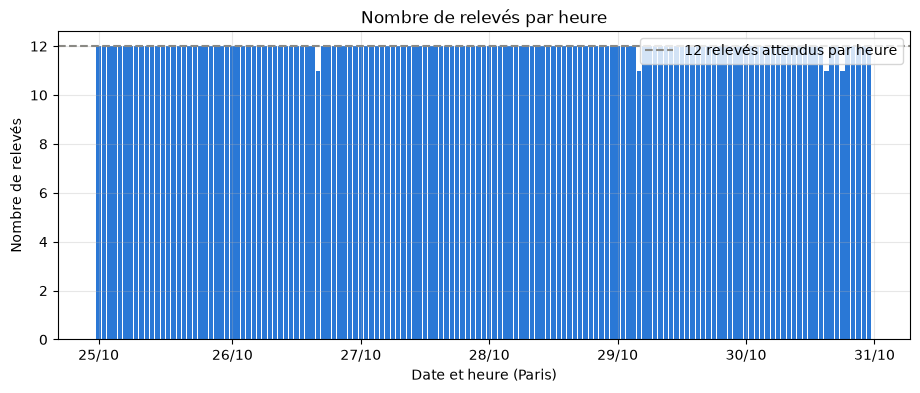

In [8]:
par_heure = releves.dt.tz_convert("UTC").dt.floor("h").dt.tz_convert("Europe/Paris").value_counts().sort_index()

plt.bar(par_heure.index, par_heure.values, width=0.035, color=BLEU)
plt.axhline(12, color=GRIS, linestyle="--", label="12 relevés attendus par heure")
plt.title("Nombre de relevés par heure")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Nombre de relevés")
plt.legend()
plt.show()

**Couverture.** Sur les six jours retenus, 1 736 des 1 740 créneaux théoriques sont observés (99,8 %). Les quatre interruptions mesurées durent dix minutes ; aucune ne dépasse quinze minutes. Le changement d'heure du 25 octobre ajoute douze créneaux à cette journée. Les observations manquantes ne sont pas interpolées pour fabriquer des cibles futures.


## 3. Qualité des données

Stations par relevé : {'min': 1519.0, 'max': 1520.0}


Stations différentes : 1520


Stations absentes du référentiel : 1

Valeurs manquantes (%) :
station_id       0.00
collecte         0.00
velos            0.00
velos_meca       1.04
velos_elec       1.04
bornes_libres    0.00
en_service       0.00
is_installed     0.00
is_returning     0.00
last_reported    0.00
temps            0.00
dtype: float64


Doublons station × créneau après nettoyage : 0
Compteurs négatifs (vélos/bornes) : 0


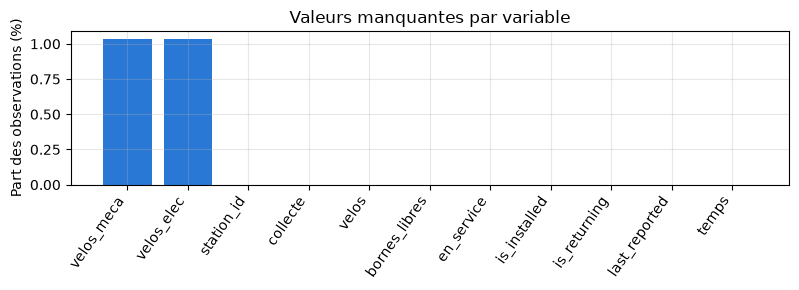

In [9]:
print("Stations par relevé :", df.groupby("temps")["station_id"].count().describe()[["min", "max"]].to_dict())
print("Stations différentes :", df["station_id"].nunique())
print("Stations absentes du référentiel :", len(set(df["station_id"]) - set(ref["station_id"])))
print()
print("Valeurs manquantes (%) :")
print((df.isna().mean() * 100).round(2))
print("Doublons station × créneau après nettoyage :", int(df.duplicated(["station_id", "temps"]).sum()))
print("Compteurs négatifs (vélos/bornes) :", int(((df["velos"] < 0) | (df["bornes_libres"] < 0)).sum()))
taux_manquants = (df.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(8, 3))
plt.bar(taux_manquants.index, taux_manquants.values, color=BLEU)
plt.title("Valeurs manquantes par variable")
plt.ylabel("Part des observations (%)")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

In [10]:
print("Répartition de en_service (%) :")
print((df["en_service"].value_counts(normalize=True) * 100).round(2))

Répartition de en_service (%) :
en_service
1    96.86
0     3.14
Name: proportion, dtype: float64


In [11]:
# Stations "muettes" : aucune nouvelle depuis plus de 24 h au dernier relevé.
dernier = df[df["temps"] == fin].copy()
dernier["age_heures"] = (fin.timestamp() - dernier["last_reported"]) / 3600
muettes = dernier[dernier["age_heures"] > 24]
print("Stations muettes :", len(muettes), "| dont déclarées en service :", (muettes["en_service"] == 1).sum())

Stations muettes : 17 | dont déclarées en service : 0


In [12]:
# Vérifications de cohérence.
df = df.merge(ref[["station_id", "capacity"]], on="station_id", how="left")
print("vélos = mécaniques + électriques :", round((df["velos"] == df["velos_meca"] + df["velos_elec"]).mean() * 100, 1), "%")
print("vélos + bornes libres = capacité :", round((df["velos"] + df["bornes_libres"] == df["capacity"]).mean() * 100, 1), "%")
print("vélos + bornes libres < capacité :", round((df["velos"] + df["bornes_libres"] < df["capacity"]).mean() * 100, 1), "%")

vélos = mécaniques + électriques : 99.0 %
vélos + bornes libres = capacité : 48.7 %
vélos + bornes libres < capacité : 50.4 %


**Qualité.** Le flux compte 1 519 puis 1 520 stations selon les jours ; il faut donc vérifier les identifiants par relevé plutôt que supposer un effectif immuable. Les compteurs par type sont absents dans certains relevés : lorsque les deux compteurs sont présents, ils correspondent au total dans 99,0 % des observations. Dans 50,4 % des observations, vélos plus bornes libres est inférieur à la capacité du référentiel ; l'écart peut notamment refléter des bornes indisponibles, sans que ce flux permette d'en attribuer chaque cas. Dix-sept stations dont `last_reported` dépasse 24 h au dernier relevé sont exclues de l'analyse.


### 3.1 Fermetures temporaires et mobilisation

`is_renting == 0` indique que la location n'est pas autorisée ; cela ne signifie pas « station vide ». Nous comptons ces stations séparément, **avant** l'exclusion des 17 stations à signalement ancien. La [Ville de Paris](https://www.paris.fr/?photo=26-12) a annoncé 110 fermetures pour les manifestations du 24 octobre, avec réouverture progressive dans la nuit du 25 au 26. [Vélib' Métropole](https://blog.velib-metropole.fr/fermeture-temporaire-de-stations-velib-a-loccasion-des-manifestations-2/) a annoncé 110 fermetures pour celles du 31 octobre, applicables dès le 30. Le flux ne fournit pas la cause individuelle d'une fermeture.

,minimum,moyenne,maximum,relevés
2026-10-25,78,160.5,167,300
2026-10-26,22,25.7,78,287
2026-10-27,20,20.6,22,288
2026-10-28,20,20.0,21,288
2026-10-29,20,20.0,20,287
2026-10-30,20,33.9,142,286


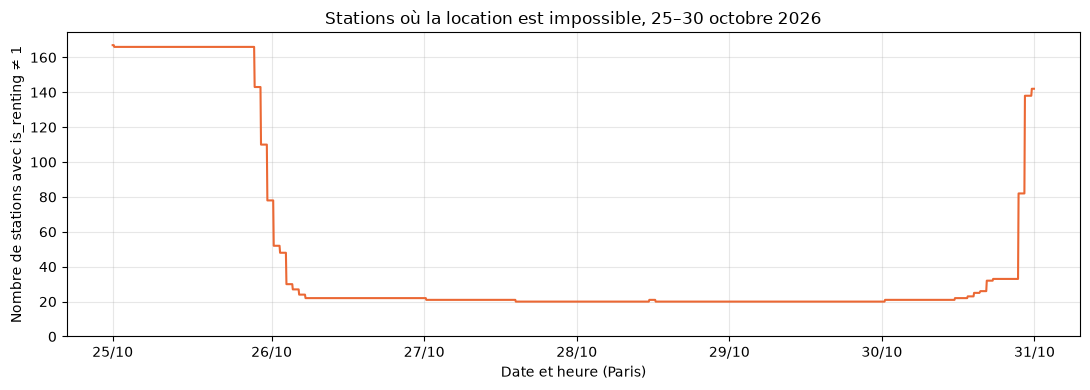

In [13]:
# Stations où l'emprunt est impossible, par relevé et par jour (avant exclusion des stations muettes).
ferme_par_releve = df.groupby("temps")["en_service"].apply(lambda valeurs: int((valeurs != 1).sum()))
fermes_par_jour = ferme_par_releve.groupby(ferme_par_releve.index.date).agg(["min", "mean", "max", "count"])
fermes_par_jour.columns = ["minimum", "moyenne", "maximum", "relevés"]
display(fermes_par_jour.round(1))
plt.figure(figsize=(11, 4))
plt.plot(ferme_par_releve.index, ferme_par_releve.values, color=ORANGE)
plt.title("Stations où la location est impossible, 25–30 octobre 2026")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Nombre de stations avec is_renting ≠ 1")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

**Lecture.** Le nombre de stations où la location est impossible atteint environ 166 le 25 octobre, redescend vers 20 en milieu de semaine, puis atteint 142 en fin de journée le 30. La concordance avec les annonces de fermeture est forte, mais ces comptes ne prouvent pas que chaque station était fermée pour cette raison. La comparaison du dimanche aux jours ouvrés est perturbée. Plus loin, la cible exclut les stations fermées à l'instant initial **ou futur** : elle répond donc à une question conditionnelle sur les stations ouvertes aux deux instants, et non au risque complet de ne pas trouver de vélo utilisable.

In [14]:
df = df[~df["station_id"].isin(muettes["station_id"])]
df["vide"] = ((df["velos"] == 0) & (df["en_service"] == 1)).astype(int)
df["pleine"] = ((df["bornes_libres"] == 0) & (df["en_service"] == 1)).astype(int)
print("Stations gardées :", df["station_id"].nunique())

Stations gardées : 1503


## 4. Le champ `last_reported`

On pourrait penser que `last_reported` donne l'heure de la dernière mise à jour de la station. On le vérifie en le comparant au nombre de stations dont le nombre de vélos change entre deux relevés.

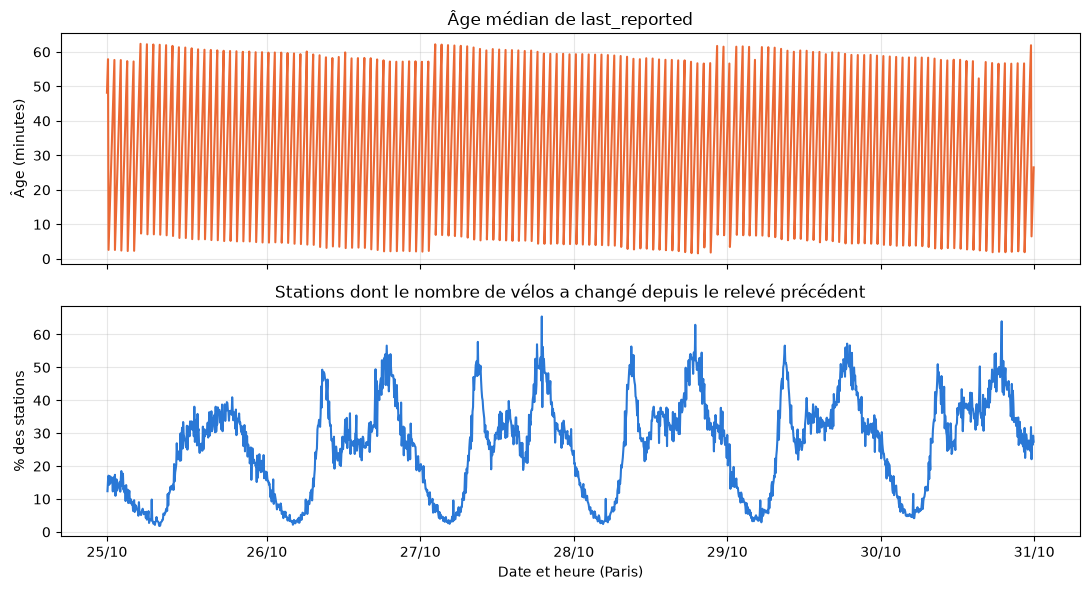

Âge médian de last_reported : 32 min
Part médiane de stations qui changent en 5 min : 28.1 %


In [15]:
df["age_last_reported_min"] = (df["collecte"] - pd.to_datetime(df["last_reported"], unit="s", utc=True)).dt.total_seconds() / 60
age_median = df.groupby("temps")["age_last_reported_min"].median()

tableau_velos = df.pivot_table(index="temps", columns="station_id", values="velos")
part_changement = ((tableau_velos.diff() != 0).mean(axis=1) * 100).iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(age_median.index, age_median.values, color=ORANGE)
axes[0].set_title("Âge médian de last_reported")
axes[0].set_ylabel("Âge (minutes)")
axes[1].plot(part_changement.index, part_changement.values, color=BLEU)
axes[1].set_title("Stations dont le nombre de vélos a changé depuis le relevé précédent")
axes[1].set_ylabel("% des stations")
axes[1].set_xlabel("Date et heure (Paris)")
plt.tight_layout()
plt.show()

print(f"Âge médian de last_reported : {age_median.median():.0f} min")
print(f"Part médiane de stations qui changent en 5 min : {part_changement.median():.1f} %")

**Interprétation prudente.** Dans cet échantillon, `last_reported` suit un rythme proche de l'heure, alors que certains compteurs changent entre deux collectes. Un âge supérieur à quinze minutes ne prouve donc pas, à lui seul, que le compteur affiché est périmé. Les colonnes `stations_stale_over_15m` et `stations_stale_over_60m` mesurent l'âge du signalement, pas une fraîcheur vérifiée des nombres de vélos.


## 5. Analyse exploratoire

Les statistiques suivantes portent sur les stations en service après exclusion des stations dont le signalement est ancien. Le taux de remplissage utilisé ici est `vélos / (vélos + bornes libres)` ; il ne doit pas être confondu avec la capacité officielle. « Presque vide » signifie au plus deux vélos, et « proche de la saturation » au moins 90 % de remplissage. La période ne couvre qu'un dimanche et cinq jours ouvrés.


In [16]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

en_service = df[df["en_service"] == 1].copy()
en_service["taux_remplissage"] = en_service["velos"] / (en_service["velos"] + en_service["bornes_libres"]).replace(0, np.nan) * 100
en_service["presque_vide"] = (en_service["velos"] <= 2).astype(int)
en_service["presque_pleine"] = (en_service["taux_remplissage"] >= 90).astype(int)
# Si le détail mécanique/électrique manque (NaN), on laisse NaN pour ne pas fausser les moyennes.
en_service["sans_elec"] = (en_service["velos_elec"] == 0).astype(float).where(en_service["velos_elec"].notna())
en_service["sans_meca"] = (en_service["velos_meca"] == 0).astype(float).where(en_service["velos_meca"].notna())

heure_paris = en_service["temps"].dt.tz_convert("Europe/Paris")
en_service["heure"] = heure_paris.dt.hour
en_service["date"] = heure_paris.dt.date
en_service["jour"] = heure_paris.dt.day_of_week.map(lambda j: JOURS[j]) + " " + heure_paris.dt.strftime("%d/%m")
print("Observations (station × relevé) :", len(en_service))

Observations (station × relevé) : 2553610


### 5.1 Statistiques descriptives

In [17]:
stats = en_service[["velos", "velos_meca", "velos_elec", "bornes_libres", "taux_remplissage", "capacity"]].describe().T
stats = stats.rename(columns={"count": "nb", "mean": "moyenne", "std": "écart-type", "min": "min",
                              "25%": "Q1", "50%": "médiane", "75%": "Q3", "max": "max"})
stats.index = ["Vélos disponibles (vélos)", "Vélos mécaniques (vélos)", "Vélos électriques (vélos)",
               "Bornes libres (bornes)", "Taux de remplissage (%)", "Capacité officielle (bornes)"]
stats.round(1)

,nb,moyenne,écart-type,min,Q1,médiane,Q3,max
Vélos disponibles (vélos),2553610.0,12.5,11.6,0.0,4.0,9.0,18.0,82.0
Vélos mécaniques (vélos),2527424.0,7.7,9.6,0.0,1.0,4.0,11.0,71.0
Vélos électriques (vélos),2527424.0,4.9,5.2,0.0,1.0,3.0,7.0,72.0
Bornes libres (bornes),2553610.0,18.8,12.3,0.0,10.0,18.0,26.0,78.0
Taux de remplissage (%),2553610.0,39.8,30.5,0.0,12.9,33.3,63.6,100.0
Capacité officielle (bornes),2552898.0,32.2,12.0,11.0,23.0,30.0,38.0,78.0


**Lecture des statistiques.** Une station en service a en moyenne 12,5 vélos et une médiane de 9 : la distribution est asymétrique. Le taux de remplissage moyen est de 39,8 %. Ces moyennes décrivent les observations station × créneau de cette période ; elles ne sont pas des moyennes saisonnières.


### 5.2 Distribution des vélos disponibles par station

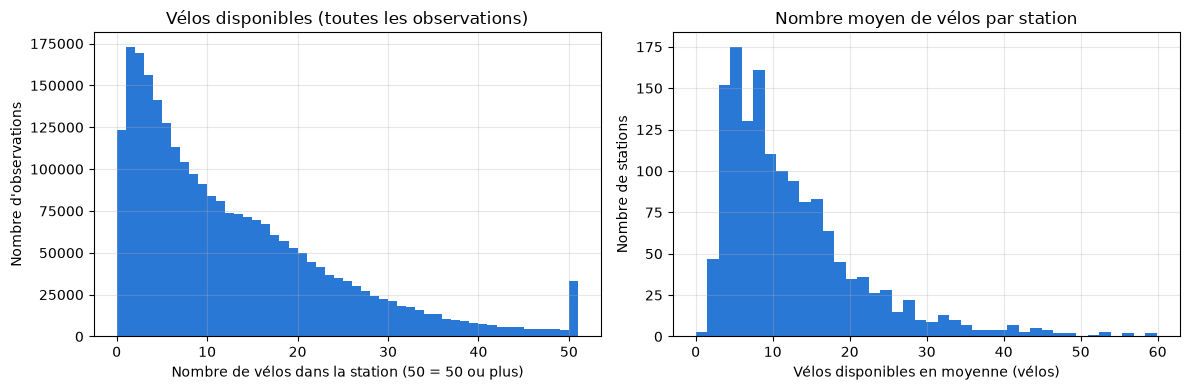

Vélos par station : moyenne 12.5, médiane 9
Observations avec 0 vélo : 4.8% | avec 2 vélos ou moins : 18.2%


In [18]:
velos_moyens_station = en_service.groupby("station_id")["velos"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(en_service["velos"].clip(upper=50), bins=range(0, 52), color=BLEU)
axes[0].set_title("Vélos disponibles (toutes les observations)")
axes[0].set_xlabel("Nombre de vélos dans la station (50 = 50 ou plus)")
axes[0].set_ylabel("Nombre d'observations")
axes[1].hist(velos_moyens_station, bins=40, color=BLEU)
axes[1].set_title("Nombre moyen de vélos par station")
axes[1].set_xlabel("Vélos disponibles en moyenne (vélos)")
axes[1].set_ylabel("Nombre de stations")
plt.tight_layout()
plt.show()

print(f"Vélos par station : moyenne {en_service['velos'].mean():.1f}, médiane {en_service['velos'].median():.0f}")
print(f"Observations avec 0 vélo : {(en_service['velos'] == 0).mean():.1%} | avec 2 vélos ou moins : {en_service['presque_vide'].mean():.1%}")

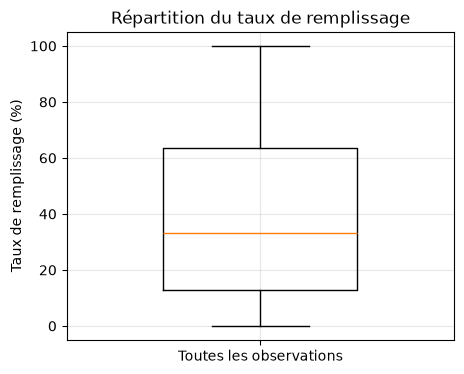

In [19]:
plt.figure(figsize=(5, 4))
plt.boxplot(en_service["taux_remplissage"].dropna(), widths=0.5)
plt.title("Répartition du taux de remplissage")
plt.ylabel("Taux de remplissage (%)")
plt.xticks([1], ["Toutes les observations"])
plt.show()

**Distribution.** Parmi les observations des stations en service, 4,8 % ont zéro vélo et 18,2 % en ont au plus deux. L'histogramme plafonne les valeurs à 50 pour rendre visible la partie dense de la distribution ; sa barre finale regroupe toutes les valeurs d'au moins 50 vélos.


### 5.3 Évolution des vélos disponibles dans le temps

Relevés sans détail mécanique/électrique : 18 sur 1736


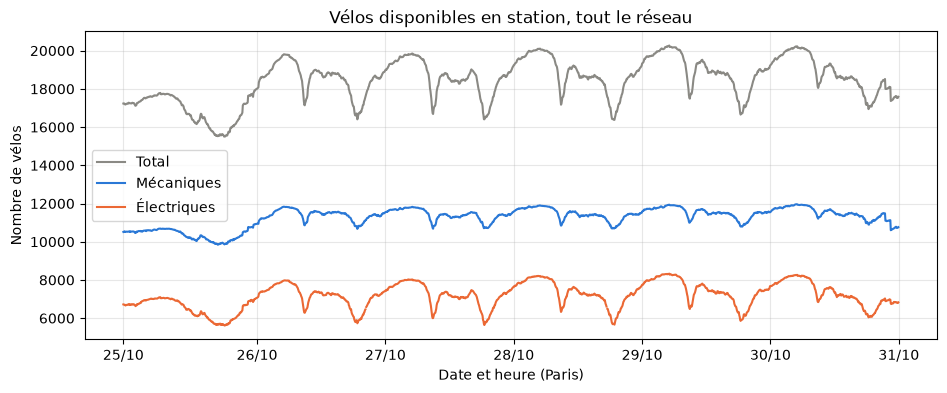

In [20]:
total = en_service.groupby("temps")[["velos", "velos_meca", "velos_elec"]].sum(min_count=1)
# Certains relevés n'ont pas le détail mécanique/électrique (voir commentaire) : on les retire de ces courbes.
detail_ok = en_service.groupby("temps")["velos_elec"].count() > 0.9 * en_service.groupby("temps")["station_id"].count()
total.loc[~detail_ok, ["velos_meca", "velos_elec"]] = np.nan
print("Relevés sans détail mécanique/électrique :", (~detail_ok).sum(), "sur", len(detail_ok))

plt.plot(total.index, total["velos"], color=GRIS, label="Total")
plt.plot(total.index, total["velos_meca"], color=BLEU, label="Mécaniques")
plt.plot(total.index, total["velos_elec"], color=ORANGE, label="Électriques")
plt.title("Vélos disponibles en station, tout le réseau")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Nombre de vélos")
plt.legend()
plt.show()

**Évolution.** Les courbes décrivent le total observé dans les stations en service. Dix-huit relevés sur 1 736 n'ont pas le détail mécanique/électrique et sont écartés uniquement des courbes par type ; le nombre total de vélos reste exploitable. La part moyenne des vélos électriques disponibles est de 38,8 %. Les variations visibles ne permettent pas, seules, d'attribuer les déplacements aux usagers ou à la régulation.


### 5.4 Stations vides et stations proches de la saturation

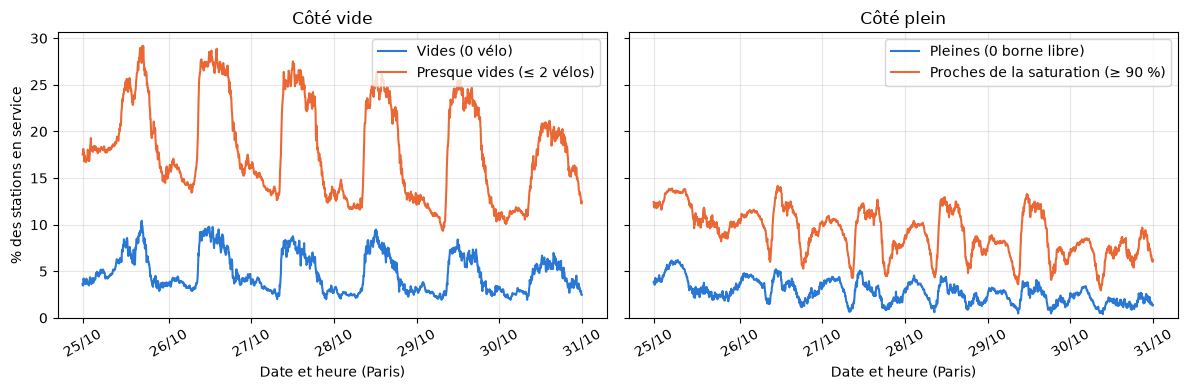

Part moyenne des stations en service (%) :
vides                                 4.8
presque vides (≤ 2 vélos)            18.3
pleines                               2.8
proches de la saturation (≥ 90 %)     9.2
dtype: float64


In [21]:
part = en_service.groupby("temps")[["vide", "presque_vide", "pleine", "presque_pleine"]].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(part.index, part["vide"], color=BLEU, label="Vides (0 vélo)")
axes[0].plot(part.index, part["presque_vide"], color=ORANGE, label="Presque vides (≤ 2 vélos)")
axes[0].set_title("Côté vide")
axes[1].plot(part.index, part["pleine"], color=BLEU, label="Pleines (0 borne libre)")
axes[1].plot(part.index, part["presque_pleine"], color=ORANGE, label="Proches de la saturation (≥ 90 %)")
axes[1].set_title("Côté plein")
for ax in axes:
    ax.set_xlabel("Date et heure (Paris)")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% des stations en service")
axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

print("Part moyenne des stations en service (%) :")
print(part.mean().round(1).rename({"vide": "vides", "presque_vide": "presque vides (≤ 2 vélos)",
                                   "pleine": "pleines", "presque_pleine": "proches de la saturation (≥ 90 %)"}))

**Stations en limite de disponibilité.** En moyenne, 4,8 % des stations en service sont vides et 18,3 % ont au plus deux vélos. Côté retour, 2,8 % n'ont aucune borne libre et 9,2 % atteignent au moins 90 % de remplissage selon le dénominateur disponible. Ces pourcentages sont des moyennes sur la période étudiée.


### 5.5 Vélos mécaniques et électriques

Part des vélos électriques parmi les vélos disponibles : 38.8 % en moyenne (min 34.4 %, max 41.3 %)
Vélos par station : 7.7 mécaniques et 4.9 électriques en moyenne
Stations sans aucun vélo électrique : 14.0% | sans aucun vélo mécanique : 20.1%


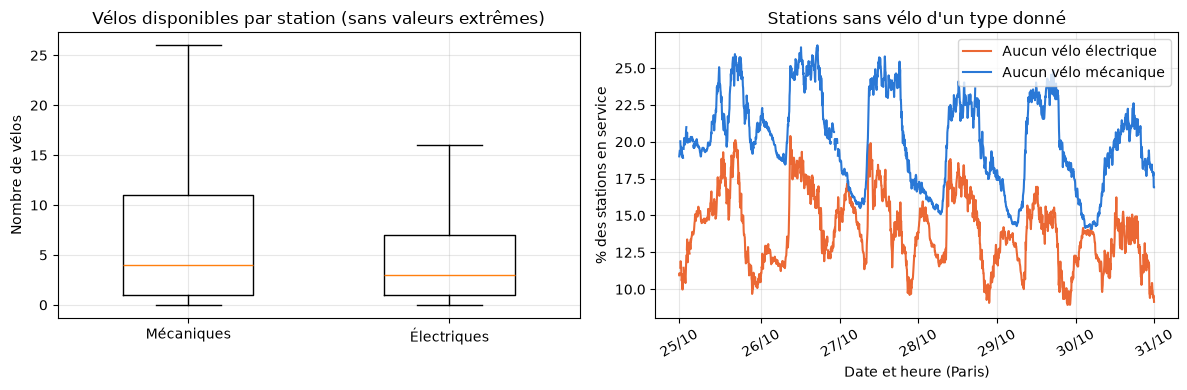

In [22]:
total["part_elec"] = total["velos_elec"] / (total["velos_meca"] + total["velos_elec"]) * 100
print(f"Part des vélos électriques parmi les vélos disponibles : {total['part_elec'].mean():.1f} % en moyenne "
      f"(min {total['part_elec'].min():.1f} %, max {total['part_elec'].max():.1f} %)")
print(f"Vélos par station : {en_service['velos_meca'].mean():.1f} mécaniques et {en_service['velos_elec'].mean():.1f} électriques en moyenne")
print(f"Stations sans aucun vélo électrique : {en_service['sans_elec'].mean():.1%} | sans aucun vélo mécanique : {en_service['sans_meca'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
donnees = [en_service["velos_meca"].dropna(), en_service["velos_elec"].dropna()]
axes[0].boxplot(donnees, showfliers=False, widths=0.5)
axes[0].set_xticks([1, 2], ["Mécaniques", "Électriques"])
axes[0].set_title("Vélos disponibles par station (sans valeurs extrêmes)")
axes[0].set_ylabel("Nombre de vélos")

sans = en_service.groupby("temps")[["sans_elec", "sans_meca"]].mean() * 100
axes[1].plot(sans.index, sans["sans_elec"], color=ORANGE, label="Aucun vélo électrique")
axes[1].plot(sans.index, sans["sans_meca"], color=BLEU, label="Aucun vélo mécanique")
axes[1].set_title("Stations sans vélo d'un type donné")
axes[1].set_xlabel("Date et heure (Paris)")
axes[1].set_ylabel("% des stations en service")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
plt.tight_layout()
plt.show()

**Types de vélos.** Les stations en service comptent en moyenne 7,7 vélos mécaniques et 4,9 électriques lorsque le détail est disponible. Environ 20,1 % des observations n'ont aucun mécanique et 14,0 % aucun électrique. Cela décrit leur répartition, sans mesurer directement la demande pour chaque type. La cible du modèle additionne les deux types.


### 5.6 Disponibilité selon la capacité des stations

,stations,vélos moyens (vélos),remplissage moyen (%),temps vide (%),temps pleine (%)
classe_capacite,,,,,
≤ 20 bornes,222,6.7,39.1,8.2,3.7
21 à 30,595,10.1,40.4,5.1,3.0
31 à 40,369,13.4,39.1,4.3,2.6
> 40 bornes,312,20.4,40.1,2.4,1.9


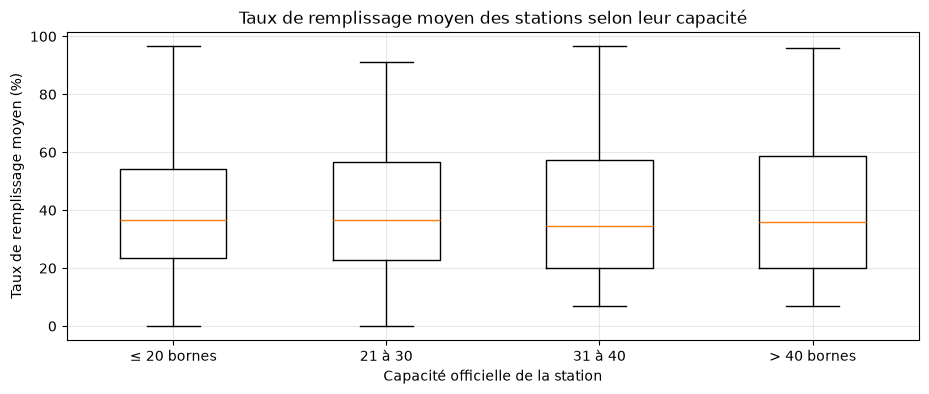

In [23]:
en_service["classe_capacite"] = pd.cut(en_service["capacity"], bins=[0, 20, 30, 40, 1000],
                                       labels=["≤ 20 bornes", "21 à 30", "31 à 40", "> 40 bornes"])

par_classe = en_service.groupby("classe_capacite", observed=True).agg(
    stations=("station_id", "nunique"),
    velos_moyens=("velos", "mean"),
    remplissage_moyen=("taux_remplissage", "mean"),
    pct_temps_vide=("vide", "mean"),
    pct_temps_pleine=("pleine", "mean"),
)
par_classe["pct_temps_vide"] *= 100
par_classe["pct_temps_pleine"] *= 100
display(par_classe.round(1).rename(columns={
    "stations": "stations", "velos_moyens": "vélos moyens (vélos)", "remplissage_moyen": "remplissage moyen (%)",
    "pct_temps_vide": "temps vide (%)", "pct_temps_pleine": "temps pleine (%)"}))

# Un point par station : son taux de remplissage moyen.
remplissage_station = en_service.groupby("station_id").agg(remplissage=("taux_remplissage", "mean"),
                                                          classe=("classe_capacite", "first"))
classes = par_classe.index
plt.boxplot([remplissage_station.loc[remplissage_station["classe"] == c, "remplissage"].dropna() for c in classes],
            widths=0.5)
plt.xticks(range(1, len(classes) + 1), classes)
plt.title("Taux de remplissage moyen des stations selon leur capacité")
plt.xlabel("Capacité officielle de la station")
plt.ylabel("Taux de remplissage moyen (%)")
plt.show()

**Capacité.** Le taux de remplissage moyen varie peu selon la classe de capacité dans ce tableau. Les stations de vingt bornes ou moins sont toutefois vides dans 8,2 % de leurs observations, contre 2,4 % pour celles de plus de quarante bornes. Il s'agit d'une association descriptive, pas d'un effet causal estimé.


### 5.7 Variations selon l'heure et le jour

/var/folders/6k/p32367qx01qdyv2w21vvntn40000gn/T/ipykernel_41774/66883402.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  part["type_jour"] = np.where(part.index.tz_convert("Europe/Paris").dayofweek >= 5, "Week-end", "Semaine")


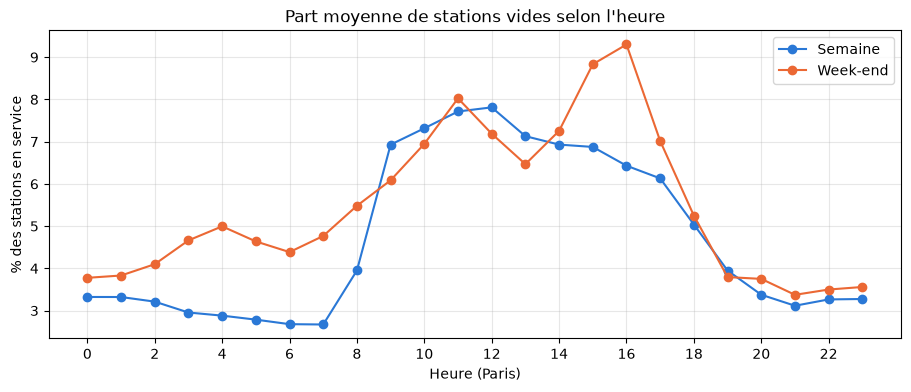

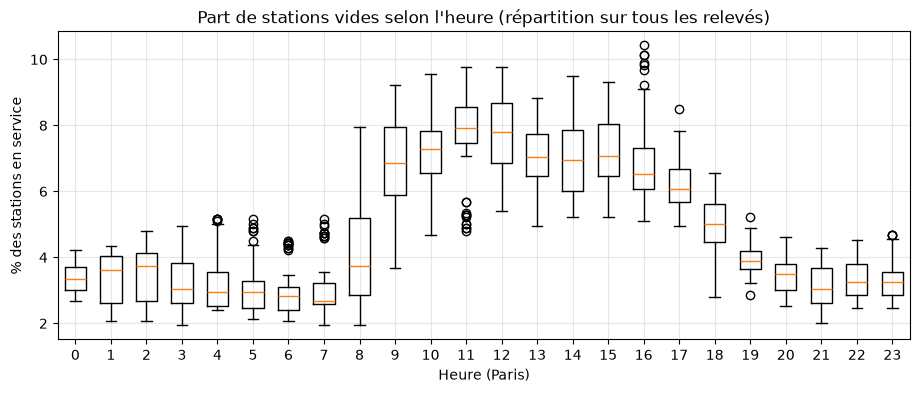

In [24]:
part["heure"] = part.index.tz_convert("Europe/Paris").hour
part["type_jour"] = np.where(part.index.tz_convert("Europe/Paris").dayofweek >= 5, "Week-end", "Semaine")
profil = part.groupby(["heure", "type_jour"])["vide"].mean().unstack().reindex(range(24))  # heure sans donnée = trou

profil.plot(marker="o", color=[BLEU, ORANGE][: profil.shape[1]])
plt.title("Part moyenne de stations vides selon l'heure")
plt.xlabel("Heure (Paris)")
plt.ylabel("% des stations en service")
plt.xticks(range(0, 24, 2))
plt.legend(title="")
plt.show()

# Boxplot : pour chaque heure, la répartition de la part de stations vides sur tous les relevés de cette heure.
heures = sorted(part["heure"].unique())
plt.boxplot([part.loc[part["heure"] == h, "vide"] for h in heures], widths=0.6)
plt.xticks(range(1, len(heures) + 1), heures)
plt.title("Part de stations vides selon l'heure (répartition sur tous les relevés)")
plt.xlabel("Heure (Paris)")
plt.ylabel("% des stations en service")
plt.show()

,"relevés (300 le 25/10, 288 ensuite)",stations vides (%),stations pleines (%),remplissage moyen (%),vélos en station (moyenne)
jour,,,,,
dimanche 25/10,300,5.4,3.7,39.5,16893.4
lundi 26/10,287,5.7,3.3,39.2,18572.1
mardi 27/10,288,4.9,2.8,39.6,18638.8
mercredi 28/10,288,4.6,2.6,40.0,18804.7
jeudi 29/10,287,4.4,2.3,40.3,18983.3
vendredi 30/10,286,4.0,1.9,40.2,18809.1


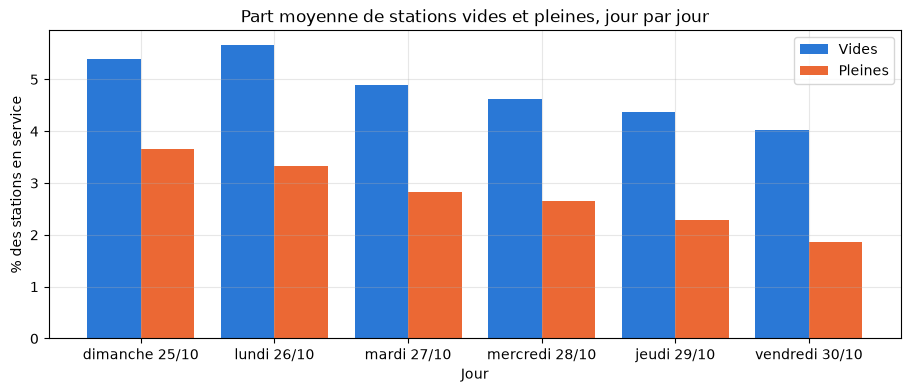

In [25]:
# Comparaison jour par jour.
total_jour = en_service.groupby(["date", "jour", "temps"])["velos"].sum().groupby(["date", "jour"]).mean()
par_jour = en_service.groupby(["date", "jour"]).agg(releves=("temps", "nunique"),
                                                    vides=("vide", "mean"), pleines=("pleine", "mean"),
                                                    remplissage=("taux_remplissage", "mean"))
par_jour["velos_reseau"] = total_jour
par_jour["vides"] *= 100
par_jour["pleines"] *= 100
par_jour = par_jour.reset_index(level="date", drop=True)
display(par_jour.round(1).rename(columns={
    "releves": "relevés (300 le 25/10, 288 ensuite)", "vides": "stations vides (%)", "pleines": "stations pleines (%)",
    "remplissage": "remplissage moyen (%)", "velos_reseau": "vélos en station (moyenne)"}))

x = np.arange(len(par_jour))
plt.bar(x - 0.2, par_jour["vides"], width=0.4, color=BLEU, label="Vides")
plt.bar(x + 0.2, par_jour["pleines"], width=0.4, color=ORANGE, label="Pleines")
plt.xticks(x, par_jour.index)
plt.title("Part moyenne de stations vides et pleines, jour par jour")
plt.xlabel("Jour")
plt.ylabel("% des stations en service")
plt.legend()
plt.show()

**Heure et jour.** Les courbes couvrent désormais toutes les heures et six journées consécutives. Le dimanche 25 octobre comporte 300 créneaux à cause du passage à l'heure d'hiver ; les autres journées en comportent 286 à 288. La comparaison jour ouvré/dimanche reste exploratoire, car elle repose sur un seul dimanche et une seule semaine.


### 5.8 Stations qui varient le plus

,station,capacité,vélos moyens,écart-type (vélos),min,max,amplitude (vélos)
1041,Pau Casals - Neuve Tolbiac,78,51.1,24.9,0,78,78
572,Assemblée Nationale,76,29.8,22.3,0,72,72
174,Gare d'Austerlitz - Pont Charles de Gaulle,75,39.9,22.1,0,73,73
1331,Gare de Lyon - Place Louis Armand,60,28.2,21.5,0,60,60
1231,Tremblay - Lac des Minimes,48,34.6,19.9,8,72,64
847,Malesherbes - Place de la Madeleine,67,23.0,19.9,1,67,66
1407,Gare de Lyon - Roland Barthes,68,41.1,19.8,1,68,67
1342,Epée de Bois - Mouffetard,63,28.1,19.3,2,61,59
1343,François 1er - Montaigne,53,23.5,19.2,0,53,53
1453,Jourdan - Stade Charléty,60,27.3,19.1,2,60,58


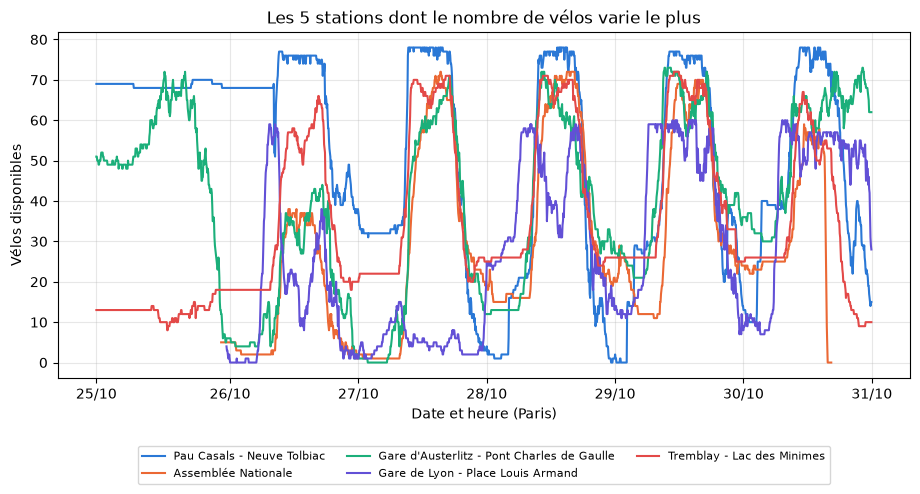

In [26]:
variations = en_service.groupby("station_id")["velos"].agg(["mean", "std", "min", "max"])
variations["amplitude"] = variations["max"] - variations["min"]
variations = variations.merge(ref[["station_id", "name", "capacity"]], on="station_id")
top_var = variations.sort_values("std", ascending=False).head(10)

display(top_var[["name", "capacity", "mean", "std", "min", "max", "amplitude"]].round(1).rename(columns={
    "name": "station", "capacity": "capacité", "mean": "vélos moyens", "std": "écart-type (vélos)",
    "amplitude": "amplitude (vélos)"}))

plt.figure(figsize=(11, 4.5))
couleurs = [BLEU, ORANGE, "#1baf7a", "#6250d6", "#e34948"]
for station_id, couleur in zip(top_var["station_id"].head(5), couleurs):
    serie = en_service[en_service["station_id"] == station_id].set_index("temps")["velos"]
    plt.plot(serie.index, serie.values, color=couleur, label=variations.set_index("station_id").loc[station_id, "name"])
plt.title("Les 5 stations dont le nombre de vélos varie le plus")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Vélos disponibles")
plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()

**Variations par station.** Les stations en tête du tableau présentent les plus fortes amplitudes de vélos disponibles sur la période. Certaines courbes montrent des changements brusques ; les données ne permettent pas d'identifier avec certitude leur cause.


### 5.9 Est-ce toujours les mêmes stations qui sont vides ?

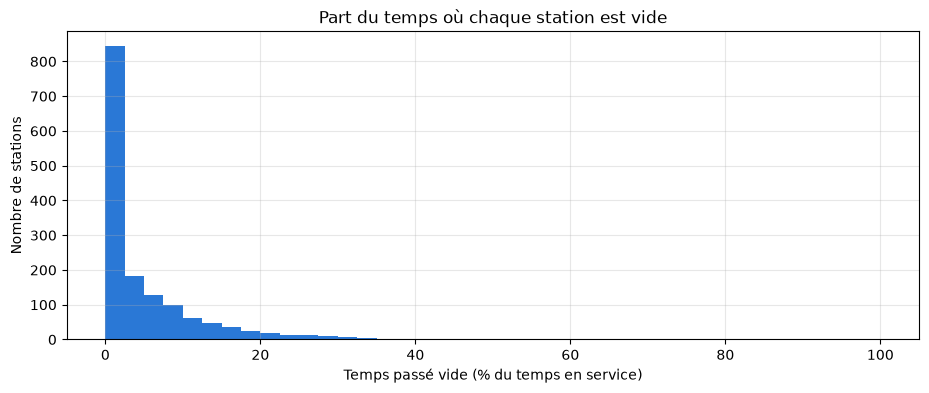

Stations jamais vides : 32%
Les 10 % de stations les plus souvent vides représentent 47% du temps vide total
Stations vides plus de 95 % du temps : 2


,station,capacité,part du temps vide
992,Place de la République - Temple,18.0,1.000000
565,Lacépède - Monge,23.0,1.000000
695,Louis Lumière - Porte de Bagnolet,20.0,0.489449
813,Frères Flavien - Porte des Lilas,23.0,0.455645
722,Lassus - Delouvain,20.0,0.411290
1137,Gambetta - Tourelles,20.0,0.361751
534,Haxo - Darcy,22.0,0.355991
501,Place des Fêtes - Solitaires,29.0,0.336982
830,Square de la rue Pixérécourt,45.0,0.325461
706,Borrégo - Gambetta,25.0,0.325461


In [27]:
par_station = en_service.groupby("station_id")["vide"].mean().to_frame("part_temps_vide")
par_station = par_station.merge(ref, on="station_id", how="left")

plt.hist(par_station["part_temps_vide"] * 100, bins=40, color=BLEU)
plt.title("Part du temps où chaque station est vide")
plt.xlabel("Temps passé vide (% du temps en service)")
plt.ylabel("Nombre de stations")
plt.show()

tri = par_station.sort_values("part_temps_vide", ascending=False)
top10 = tri.head(len(tri) // 10)
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Les 10 % de stations les plus souvent vides représentent {top10['part_temps_vide'].sum() / tri['part_temps_vide'].sum():.0%} du temps vide total")
print(f"Stations vides plus de 95 % du temps : {(par_station['part_temps_vide'] > 0.95).sum()}")
tri.head(10)[["name", "capacity", "part_temps_vide"]].rename(columns={"name": "station", "capacity": "capacité",
                                                                     "part_temps_vide": "part du temps vide"})

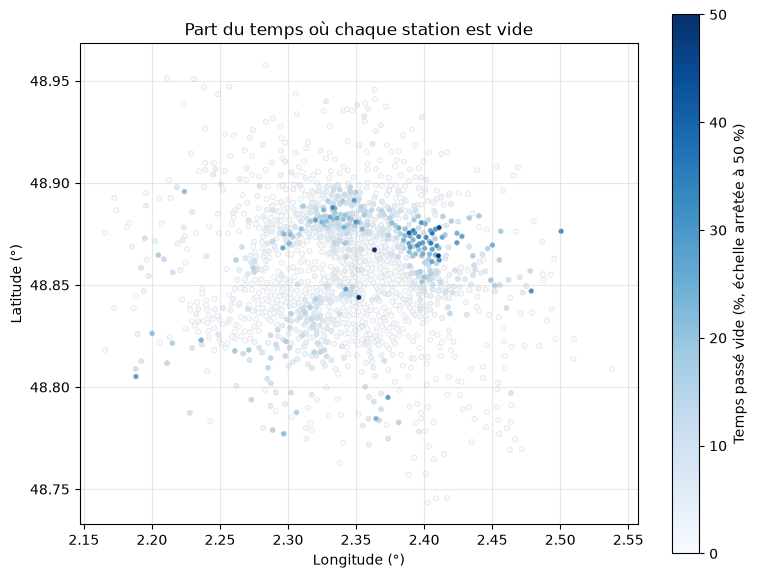

In [28]:
carte = par_station.sort_values("part_temps_vide")   # les stations souvent vides sont dessinées par-dessus
plt.figure(figsize=(9, 7))
plt.scatter(carte["lon"], carte["lat"], c=carte["part_temps_vide"] * 100,
            cmap="Blues", s=14, vmax=50, edgecolors="lightgray", linewidths=0.3)
plt.colorbar(label="Temps passé vide (%, échelle arrêtée à 50 %)")
plt.title("Part du temps où chaque station est vide")
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.gca().set_aspect(1.5)   # pour que Paris ne soit pas écrasé
plt.show()

**Concentration spatiale.** Sur la période retenue, 32 % des stations analysées ne sont jamais vides et les 10 % les plus souvent vides concentrent 47 % des observations de station vide. Deux stations sont vides pendant plus de 95 % de leurs observations en service. La carte suggère des regroupements, mais aucun test spatial n'est effectué ; il faut donc éviter d'en déduire une cause géographique.


### 5.10 Carte interactive et secteurs descriptifs

La carte utilise **toutes les stations étudiées ayant des coordonnées valides**. Une station est classée « souvent vide » lorsqu'elle est vide dans au moins 20 % de ses observations **en service** pendant les six jours ; ce seuil sert uniquement à l'exploration. Les couches peuvent être affichées séparément, et le survol indique le nom de la station. La couleur représente la part du temps vide, tandis que la fenêtre d'information donne aussi le nombre moyen de vélos observés.

Les quatre secteurs ci-dessous sont définis par les médianes de latitude et longitude de cet échantillon. Ils ne correspondent pas à des arrondissements ou à une frontière administrative. Une différence entre secteurs est descriptive et n'établit pas une cause géographique.

In [29]:
import html
import folium

geo = par_station.merge(
    en_service.groupby("station_id").agg(
        velos_moyens=("velos", "mean"), observations=("velos", "size")
    ).reset_index(), on="station_id", how="inner"
)
geo = geo[geo["lat"].between(-90, 90) & geo["lon"].between(-180, 180)].copy()
assert geo["station_id"].is_unique
print(f"Stations cartographiées : {len(geo)} / {len(par_station)}")

lat_centre, lon_centre = geo["lat"].median(), geo["lon"].median()
geo["secteur"] = np.select(
    [
        (geo["lat"] >= lat_centre) & (geo["lon"] < lon_centre),
        (geo["lat"] >= lat_centre) & (geo["lon"] >= lon_centre),
        (geo["lat"] < lat_centre) & (geo["lon"] < lon_centre),
    ],
    ["Nord-Ouest", "Nord-Est", "Sud-Ouest"], default="Sud-Est"
)
secteurs = geo.groupby("secteur").agg(
    stations=("station_id", "size"),
    part_vide_moyenne=("part_temps_vide", "mean"),
    velos_moyens=("velos_moyens", "mean")
)
secteurs["part_vide_moyenne"] *= 100
display(secteurs.round(1).rename(columns={
    "stations": "stations", "part_vide_moyenne": "temps vide moyen (%)",
    "velos_moyens": "vélos moyens par station"
}))
print("Secteur avec la plus forte part moyenne de temps vide :", secteurs["part_vide_moyenne"].idxmax())

carte_interactive = folium.Map(
    location=[lat_centre, lon_centre], zoom_start=12,
    tiles="OpenStreetMap", prefer_canvas=True, control_scale=True
)
souvent_vides = folium.FeatureGroup(name="Souvent vides (≥ 20 %)")
autres = folium.FeatureGroup(name="Autres stations")
for station in geo.itertuples():
    part_vide = float(station.part_temps_vide)
    couleur = "#cf3f3f" if part_vide >= 0.20 else "#e89b32" if part_vide >= 0.05 else "#348d99" if part_vide > 0 else "#3865b0"
    nom = html.escape(str(station.name))
    info = (f"<b>{nom}</b><br>Vides : {part_vide:.1%} du temps en service"
            f"<br>Vélos moyens : {station.velos_moyens:.1f}"
            f"<br>Observations : {station.observations:,}")
    folium.CircleMarker(
        location=[station.lat, station.lon], radius=4, color=couleur,
        fill=True, fill_color=couleur, fill_opacity=0.8, weight=0.4,
        tooltip=nom, popup=folium.Popup(info, max_width=270)
    ).add_to(souvent_vides if part_vide >= 0.20 else autres)
souvent_vides.add_to(carte_interactive)
autres.add_to(carte_interactive)
folium.LayerControl(collapsed=False).add_to(carte_interactive)
legende = '''<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;
padding:9px;border:1px solid #777;font:12px sans-serif">
<b>Temps passé vide en service</b><br>
<span style="color:#3865b0">●</span> 0 % &nbsp;
<span style="color:#348d99">●</span> &gt;0 à &lt;5 % &nbsp;
<span style="color:#e89b32">●</span> 5 à &lt;20 % &nbsp;
<span style="color:#cf3f3f">●</span> ≥20 %</div>'''
carte_interactive.get_root().html.add_child(folium.Element(legende))
chemin_carte = os.path.join(DOSSIER, "docs", "carte-stations.html")
carte_interactive.save(chemin_carte)
print("Carte HTML enregistrée :", chemin_carte)
carte_interactive

Stations cartographiées : 1498 / 1499


,stations,temps vide moyen (%),vélos moyens par station
secteur,,,
Nord-Est,370,8.0,8.6
Nord-Ouest,379,4.6,11.6
Sud-Est,379,2.9,16.8
Sud-Ouest,370,3.7,13.2


Secteur avec la plus forte part moyenne de temps vide : Nord-Est


Carte HTML enregistrée : ./docs/carte-stations.html


**Lecture spatiale.** Le tableau par secteurs compare des moyennes de stations, sans pondération par le nombre de passages ni par les trajets. La carte peut aider à repérer des stations fréquemment vides, mais six journées perturbées et l'absence de données de demande ne permettent pas d'attribuer les écarts à la localisation seule.

### 5.11 Tableau de synthèse des indicateurs descriptifs

In [30]:
synthese = pd.DataFrame([
    ("Période observée", f"{debut.tz_convert('Europe/Paris'):%d/%m %H:%M} → {fin.tz_convert('Europe/Paris'):%d/%m %H:%M}", ""),
    ("Durée de collecte", round(duree_heures, 1), "heures"),
    ("Relevés obtenus / attendus", f"{len(releves)} / {attendus}", "relevés"),
    ("Stations analysées", df["station_id"].nunique(), "stations"),
    ("Stations hors service (en moyenne)", round((1 - df.groupby("temps")["en_service"].mean().mean()) * 100, 1), "%"),
    ("Vélos disponibles dans le réseau (moyenne)", round(total["velos"].mean()), "vélos"),
    ("Part de vélos électriques", round(total["part_elec"].mean(), 1), "%"),
    ("Vélos par station (moyenne)", round(en_service["velos"].mean(), 1), "vélos"),
    ("Vélos par station (médiane)", en_service["velos"].median(), "vélos"),
    ("Taux de remplissage moyen", round(en_service["taux_remplissage"].mean(), 1), "%"),
    ("Stations vides", round(part["vide"].mean(), 1), "% des stations"),
    ("Stations presque vides (≤ 2 vélos)", round(part["presque_vide"].mean(), 1), "% des stations"),
    ("Stations pleines", round(part["pleine"].mean(), 1), "% des stations"),
    ("Stations proches de la saturation (≥ 90 %)", round(part["presque_pleine"].mean(), 1), "% des stations"),
    ("Stations sans vélo électrique", round(en_service["sans_elec"].mean() * 100, 1), "% des stations"),
    ("Stations jamais vides sur la période", round((par_station["part_temps_vide"] == 0).mean() * 100, 1), "% des stations"),
    ("Stations vides plus de 95 % du temps", int((par_station["part_temps_vide"] > 0.95).sum()), "stations"),
], columns=["indicateur", "valeur", "unité"])
synthese

,indicateur,valeur,unité
0,Période observée,25/10 00:00 → 30/10 23:55,
1,Durée de collecte,144.9,heures
2,Relevés obtenus / attendus,1736 / 1740,relevés
3,Stations analysées,1503,stations
4,Stations hors service (en moyenne),2.1,%
5,Vélos disponibles dans le réseau (moyenne),18439,vélos
6,Part de vélos électriques,38.8,%
7,Vélos par station (moyenne),12.5,vélos
8,Vélos par station (médiane),9.0,vélos
9,Taux de remplissage moyen,39.8,%


### Synthèse de l'exploration

La période du 25 au 30 octobre couvre 1 736 des 1 740 créneaux attendus. Après exclusion de dix-sept stations à signalement ancien, 1 503 stations apparaissent dans l'analyse des statuts. Les stations en service sont vides dans 4,8 % des observations et presque vides (au plus deux vélos) dans 18,3 %. Les stations petites présentent plus souvent des observations vides que les grandes. La collecte devient très espacée après le 31 octobre ; ces relevés tardifs ne sont pas mélangés avec la période étudiée. Les tendances selon l'heure et le jour restent descriptives et ne démontrent ni saisonnalité ni causalité.


## 6. Construction de la cible et variables explicatives

Pour chaque station et chaque instant *t*, on cherche l'état de la même station à *t* + 30 min avec une jointure exacte. Les variations à 15 et 30 minutes ainsi que la moyenne mobile sur les 30 minutes **passées** mesurent l'évolution récente. L'heure, le jour de la semaine et la période de la journée sont calculés à l'instant *t*. Aucune variable explicative n'utilise une observation postérieure à *t*.

In [31]:
def decaler(df, minutes, suffixe):
    """Renvoie les vélos et l'état de service décalés dans le temps, pour les fusionner avec df."""
    copie = df[["station_id", "temps", "velos", "en_service"]].copy()
    copie["temps"] = copie["temps"] - pd.Timedelta(minutes=minutes)
    return copie.rename(columns={"velos": "velos" + suffixe, "en_service": "en_service" + suffixe})


# État dans 30 minutes (pour la cible)
data = df.merge(decaler(df, 30, "_futur"), on=["station_id", "temps"], how="inner")

# État il y a 15 et 30 minutes (variables explicatives)
data = data.merge(decaler(df, -15, "_moins15"), on=["station_id", "temps"], how="left")
data = data.merge(decaler(df, -30, "_moins30"), on=["station_id", "temps"], how="left")

# On garde les stations en service maintenant et dans 30 minutes.
data = data[(data["en_service"] == 1) & (data["en_service_futur"] == 1)].copy()
data["cible"] = (data["velos_futur"] == 0).astype(int)

print("Nombre d'exemples :", len(data))
print(f"Part de stations vides dans 30 min : {data['cible'].mean():.1%}")

Nombre d'exemples : 2538642
Part de stations vides dans 30 min : 4.8%


In [32]:
# Moyenne mobile fondée uniquement sur les observations en service jusqu'à t inclus.
historique_30 = (
    df.loc[df["en_service"] == 1, ["station_id", "temps", "velos"]]
      .sort_values(["station_id", "temps"])
      .groupby("station_id")
      .rolling("30min", on="temps", closed="both")["velos"]
      .agg(["mean", "count"])
      .reset_index()
      .rename(columns={"mean": "moyenne_velos_30min", "count": "nb_releves_30min"})
)
data = data.merge(historique_30, on=["station_id", "temps"], how="left", validate="one_to_one")
data["historique_court"] = (data["nb_releves_30min"] < 4).astype(int)
data.loc[data["historique_court"] == 1, "moyenne_velos_30min"] = data["velos"]

# Variables explicatives observables à l'instant t.
data["vide_maintenant"] = (data["velos"] == 0).astype(int)
data["taux_remplissage"] = data["velos"] / (data["velos"] + data["bornes_libres"]).replace(0, np.nan)
data["variation_15min"] = data["velos"] - data["velos_moins15"]
data["variation_30min"] = data["velos"] - data["velos_moins30"]
heure_locale = data["temps"].dt.tz_convert("Europe/Paris")
data["heure"] = heure_locale.dt.hour
data["jour_semaine"] = heure_locale.dt.day_of_week
data["week_end"] = (data["jour_semaine"] >= 5).astype(int)
data["periode_jour"] = np.select(
    [data["heure"] < 6, data["heure"] < 12, data["heure"] < 18],
    [0, 1, 2], default=3
).astype(int)  # 0 nuit, 1 matin, 2 après-midi, 3 soirée
data = data.merge(ref[["station_id", "lat", "lon"]], on="station_id", how="left")
data = data.dropna(subset=["lat", "lon"])

# Un historique insuffisant est signalé ; sa moyenne est remplacée par le compteur actuel.
# Les variations passées absentes restent une limite et sont imputées à zéro.
for col in ["taux_remplissage", "variation_15min", "variation_30min", "velos_elec"]:
    data[col] = data[col].fillna(0)
assert data["moyenne_velos_30min"].notna().all()
assert data["nb_releves_30min"].between(1, 7).all()
print("Historique court (<4 relevés sur 30 min) :", f"{data['historique_court'].mean():.2%}")


Historique court (<4 relevés sur 30 min) : 0.18%


**Dictionnaire des nouvelles variables (à l'instant de prédiction).**

| Variable | Définition | Traitement des trous |
| --- | --- | --- |
| `jour_semaine`, `periode_jour` | Jour local (0 = lundi) ; nuit 0–5 h, matin 6–11 h, après-midi 12–17 h, soirée 18–23 h | Heure locale explicite, y compris au changement d'heure |
| `taux_remplissage` | Vélos / (vélos + bornes libres) | 0 si dénominateur nul, convention analytique |
| `variation_15min`, `variation_30min` | Vélos à *t* moins vélos observés exactement 15/30 min avant | 0 si le relevé passé manque ; limite à interpréter |
| `moyenne_velos_30min` | Moyenne des compteurs en service de *t−30* à *t*, bornes incluses | Remplacée par le compteur actuel si moins de 4 relevés |
| `nb_releves_30min`, `historique_court` | Nombre de relevés disponibles (1 à 7) et indicateur de moins de 4 | Signalent explicitement la couverture récente |
| `historique_station` | Fréquence de vide calculée sur l'entraînement seulement | Valeur moyenne des stations d'entraînement si station inconnue |

Ces variables sont toutes calculées avant la décision à *t*. La population de test reste conditionnée à l'état de service futur, comme expliqué dans la définition de la cible.

In [33]:
# Tableau clé : que devient une station 30 minutes plus tard ?
pd.crosstab(data["vide_maintenant"], data["cible"], normalize="index").round(3) * 100

cible,0,1
vide_maintenant,,
0,98.1,1.9
1,38.4,61.6


**Baseline.** Une station déjà vide à *t* le reste souvent à *t* + 30 minutes ; la règle de persistance est donc un comparateur exigeant. Pour les stations qui disposent encore de vélos, cette règle prédit toujours « non vide » et son rappel des passages à vide est nul. La précision, le rappel, le F1 et l'aire sous la courbe précision-rappel sont plus informatifs que l'accuracy pour cet événement rare.


## 7. Modèles et évaluation

**Découpage dans l'ordre du temps.** On coupe la période en trois morceaux successifs :
- **entraînement** (60 % du temps) : pour apprendre les modèles ;
- **validation** (15 %) : pour choisir le seuil de décision ;
- **test** (25 % restants) : pour l'évaluation finale, utilisé une seule fois.

On ne mélange pas au hasard : deux relevés espacés de 5 minutes se ressemblent presque toujours, un découpage aléatoire donnerait donc des scores trop optimistes. On laisse aussi un écart de 30 minutes avant chaque coupure, pour que la cible d'une période ne tombe pas dans la période suivante.

In [34]:
t_debut = data["temps"].min()
duree = data["temps"].max() - t_debut
marge = pd.Timedelta(minutes=30)
coupure_valid = t_debut + 0.60 * duree
coupure_test = t_debut + 0.75 * duree

train = data[data["temps"] < coupure_valid - marge].copy()
valid = data[(data["temps"] >= coupure_valid) & (data["temps"] < coupure_test - marge)].copy()
test = data[data["temps"] >= coupure_test].copy()

for nom, partie in [("Entraînement", train), ("Validation", valid), ("Test", test)]:
    print(f"{nom:13}: {partie['temps'].min().tz_convert('Europe/Paris'):%d/%m %H:%M} → "
          f"{partie['temps'].max().tz_convert('Europe/Paris'):%d/%m %H:%M} | {len(partie)} lignes | "
          f"{partie['cible'].mean():.1%} de positifs")

Entraînement : 25/10 00:00 → 28/10 13:05 | 1502276 lignes | 5.2% de positifs
Validation   : 28/10 13:40 → 29/10 10:45 | 377496 lignes | 4.1% de positifs
Test         : 29/10 11:20 → 30/10 23:25 | 640191 lignes | 4.3% de positifs


In [35]:
# Historique de chaque station : part du temps vide, calculée SEULEMENT sur l'entraînement.
historique = train.groupby("station_id")["vide_maintenant"].mean()
for partie in [train, valid, test]:
    partie["historique_station"] = partie["station_id"].map(historique).fillna(historique.mean())

variables = ["velos", "bornes_libres", "velos_elec", "taux_remplissage", "variation_15min",
             "variation_30min", "moyenne_velos_30min", "nb_releves_30min", "historique_court",
             "heure", "jour_semaine", "periode_jour", "week_end", "historique_station", "lat", "lon"]

X_test, y_test = test[variables], test["cible"]

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

# Pour que l'entraînement reste rapide sur Colab, on prend au plus 300 000 lignes au hasard.
echantillon = train.sample(min(len(train), 300_000), random_state=0)

modele_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele_lr.fit(echantillon[variables], echantillon["cible"])

modele_rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                                   n_jobs=-1, random_state=0)
modele_rf.fit(echantillon[variables], echantillon["cible"])
print("Modèles entraînés")

Modèles entraînés


In [37]:
# Choix du seuil sur la validation.
# Par défaut, predict() prédit "vide" si la probabilité dépasse 0,5. Comme les stations vides sont rares,
# ce seuil est trop strict : on teste plusieurs seuils et on garde celui qui donne le meilleur F1.
seuils = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
modeles = {"Régression logistique": modele_lr, "Random forest": modele_rf}
meilleur_seuil = {}
tableau_seuils = pd.DataFrame(index=seuils)

for nom, modele in modeles.items():
    proba_valid = modele.predict_proba(valid[variables])[:, 1]
    tableau_seuils[nom] = [f1_score(valid["cible"], proba_valid >= s) for s in seuils]
    meilleur_seuil[nom] = float(tableau_seuils[nom].idxmax())

print("F1 sur la validation selon le seuil :")
display(tableau_seuils.round(3))
print("Seuils retenus :", meilleur_seuil)

F1 sur la validation selon le seuil :


,Régression logistique,Random forest
0.10,0.461,0.508
0.15,0.506,0.554
0.20,0.545,0.588
0.25,0.563,0.602
0.30,0.575,0.606
0.35,0.571,0.606
0.40,0.555,0.599
0.50,0.453,0.561


Seuils retenus : {'Régression logistique': 0.3, 'Random forest': 0.3}


In [38]:
def evaluer(nom, y_vrai, y_pred, proba=None):
    resultat = {
        "modèle": nom,
        "précision": precision_score(y_vrai, y_pred, zero_division=0),
        "rappel": recall_score(y_vrai, y_pred, zero_division=0),
        "F1": f1_score(y_vrai, y_pred, zero_division=0),
    }
    if proba is not None:
        resultat["PR-AUC"] = average_precision_score(y_vrai, proba)
    return resultat


predictions = {"Persistance": (test["vide_maintenant"].to_numpy(), None)}
for nom, modele in modeles.items():
    proba_test = modele.predict_proba(X_test)[:, 1]
    predictions[nom] = ((proba_test >= meilleur_seuil[nom]).astype(int), proba_test)

# Résultats sur tout le test
resultats = pd.DataFrame([evaluer(nom, y_test, pred, proba) for nom, (pred, proba) in predictions.items()])
print("Toutes les stations du test :")
display(resultats.round(3))

# Résultats sur les stations qui ont encore des vélos : peut-on prévoir qu'elles vont se vider ?
non_vides = (test["vide_maintenant"] == 0).to_numpy()
resultats_non_vides = pd.DataFrame([
    evaluer(nom, y_test[non_vides], pred[non_vides], None if proba is None else proba[non_vides])
    for nom, (pred, proba) in predictions.items()
])
print("Stations qui ont encore des vélos maintenant :")
display(resultats_non_vides.round(3))

Toutes les stations du test :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.560,0.565,0.562,NaN
1,Régression logistique,0.502,0.615,0.553,0.527
2,Random forest,0.550,0.590,0.570,0.585


Stations qui ont encore des vélos maintenant :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.000,0.000,0.000,NaN
1,Régression logistique,0.247,0.136,0.176,0.184
2,Random forest,0.354,0.104,0.160,0.225


In [39]:
# Matrice de confusion du random forest
pd.DataFrame(confusion_matrix(y_test, predictions["Random forest"][0]),
             index=["réel : pas vide", "réel : vide"], columns=["prédit : pas vide", "prédit : vide"])

,prédit : pas vide,prédit : vide
réel : pas vide,599120,13364
réel : vide,11353,16354


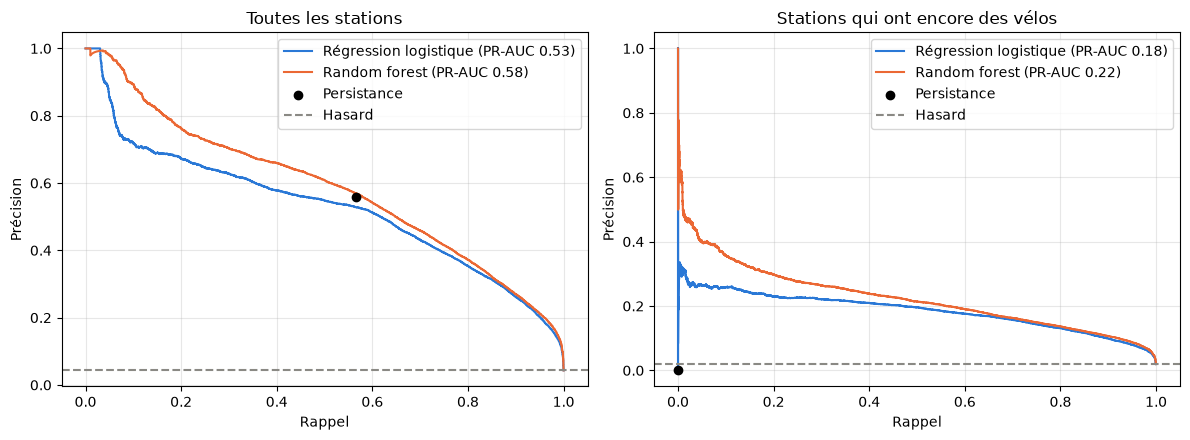

In [40]:
# Courbes précision-rappel : on voit tous les compromis possibles, pas seulement le seuil 0,5.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, masque, titre in [(axes[0], np.ones(len(y_test), dtype=bool), "Toutes les stations"),
                          (axes[1], non_vides, "Stations qui ont encore des vélos")]:
    for nom, couleur in [("Régression logistique", BLEU), ("Random forest", ORANGE)]:
        proba = predictions[nom][1][masque]
        precision, rappel, _ = precision_recall_curve(y_test[masque], proba)
        ax.plot(rappel, precision, color=couleur, label=f"{nom} (PR-AUC {average_precision_score(y_test[masque], proba):.2f})")
    p = precision_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    r = recall_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    ax.scatter(r, p, color="black", zorder=3, label="Persistance")
    ax.axhline(y_test[masque].mean(), color=GRIS, linestyle="--", label="Hasard")
    ax.set_title(titre)
    ax.set_xlabel("Rappel")
    ax.set_ylabel("Précision")
    ax.legend()
plt.tight_layout()
plt.show()

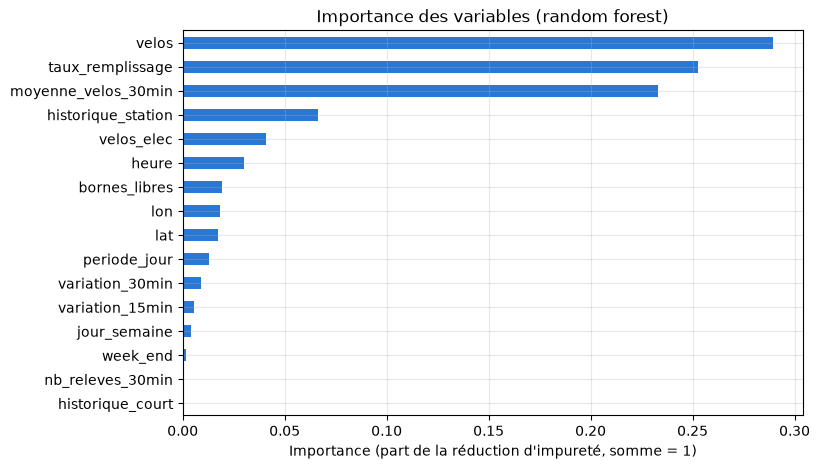

In [41]:
# Importance des variables (random forest)
importance = pd.Series(modele_rf.feature_importances_, index=variables).sort_values()
importance.plot(kind="barh", color=BLEU, figsize=(8, 5))
plt.title("Importance des variables (random forest)")
plt.xlabel("Importance (part de la réduction d'impureté, somme = 1)")
plt.show()

**Résultats sur le test chronologique.** Sur toutes les stations, la forêt aléatoire obtient un F1 de 0,570 et la persistance 0,562 : l'écart de 0,008, mesuré sur une seule coupure, ne prouve pas un gain stable. La régression logistique obtient 0,553. Parmi les stations encore pourvues de vélos, la régression logistique atteint un rappel de 0,136 (F1 0,176), et la forêt une précision de 0,354 mais un rappel de 0,104 (F1 0,160). Les seuils ont été choisis sur la validation, pas sur le test. Une seule coupure chronologique ne mesure pas la stabilité des scores entre semaines.


La fermeture temporaire de nombreuses stations autour des manifestations des 24 et 31 octobre est une perturbation documentée. Elle touche le début de la période et la fin du test ; le flux ne permet pas d'en attribuer individuellement la cause. Les scores portent seulement sur les stations ouvertes aux deux instants.

## 8. Conclusion et limites

In [42]:
# Chiffres clés, recalculés à chaque exécution (à reprendre dans le rapport).
print(f"Période : {debut.tz_convert('Europe/Paris'):%d/%m %H:%M} → {fin.tz_convert('Europe/Paris'):%d/%m %H:%M}, {duree_heures:.0f} h, couverture {len(releves) / attendus:.1%}")
print(f"Stations analysées : {df['station_id'].nunique()} ({len(muettes)} stations muettes retirées)")
print(f"Stations vides en moyenne : {part['vide'].mean():.1f} %")
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Vide dans 30 min si vide maintenant : {data.loc[data['vide_maintenant'] == 1, 'cible'].mean():.0%} ; si non vide : {data.loc[data['vide_maintenant'] == 0, 'cible'].mean():.1%}")
print()
print(resultats.set_index("modèle").round(2))
print()
print(resultats_non_vides.set_index("modèle").round(2))

Période : 25/10 00:00 → 30/10 23:55, 145 h, couverture 99.8%
Stations analysées : 1503 (17 stations muettes retirées)
Stations vides en moyenne : 4.8 %
Stations jamais vides : 32%
Vide dans 30 min si vide maintenant : 62% ; si non vide : 1.9%

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.56    0.57  0.56     NaN
Régression logistique       0.50    0.61  0.55    0.53
Random forest               0.55    0.59  0.57    0.58

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.00    0.00  0.00     NaN
Régression logistique       0.25    0.14  0.18    0.18
Random forest               0.35    0.10  0.16    0.22


L'historique dense du 25 au 30 octobre, perturbé par des fermetures temporaires de stations, permet une analyse descriptive et une preuve de concept pour la cible « vide exactement à +30 minutes ». Le modèle de classification le plus performant selon le F1 global ne dépasse la persistance que de 0,008 sur cette seule coupure ; aucun gain robuste n'est démontré. La détection des stations encore non vides reste difficile. Les résultats concernent six jours d'automne, avec une seule découpe entraînement/validation/test, et ne permettent aucune conclusion sur les saisons, la météo ou d'autres semaines.

Les mesures reposent sur des instantanés, pas sur les trajets individuels. Le champ `last_reported` ne garantit pas que chaque compteur ait été rafraîchi à l'instant de collecte. La cible regroupe vélos mécaniques et électriques et exclut les stations hors service aux deux instants observés. Les trous sans observation à +30 minutes ne sont pas interpolés.

**Sources :** flux GBFS Vélib' Métropole `station_status.json` et `station_information.json` ; [documentation officielle des données ouvertes](https://www.velib-metropole.fr/fr/donnees-open-data-gbfs-du-service-velib-metropole).

## 9. Expérience complémentaire : nombre de vélos à +30 minutes

La régression ci-dessous prédit le nombre de vélos, puis examine rétrospectivement les erreurs et les stations avec peu de vélos prédits. Elle obtient une erreur absolue moyenne de **1,45 vélo**, contre **1,34** pour la règle « nombre inchangé » sur le même test. Elle n'apporte donc pas de gain démontré et ne constitue pas une alerte opérationnelle.


**Réponse à la question.** On peut construire et évaluer la cible exacte à +30 minutes sur les stations ouvertes aux deux instants, mais les modèles testés ne surpassent pas de façon convaincante la persistance. Parmi les stations encore pourvues de vélos, le rappel reste faible. La question opérationnelle plus large inclurait aussi les fermetures futures, que cette cible exclut ; aucune alerte fiable n'est donc établie.

In [43]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# On prédit le nombre de vélos dans 30 minutes
cible = "velos_futur"

modele = RandomForestRegressor(n_estimators=100, random_state=0)
modele.fit(echantillon[variables], echantillon[cible])

print("Modèle entraîné")

Modèle entraîné


In [44]:
# Prédictions du modèle
prediction = modele.predict(X_test)

# On interdit les nombres négatifs
prediction = prediction.clip(min=0)

# Règle simple : le nombre de vélos ne change pas
prediction_simple = test["velos"]

# Vraie valeur à prédire
vrai = test[cible]

print("Erreur moyenne du modèle :", round(mean_absolute_error(vrai, prediction), 2), "vélos")
print("Erreur moyenne de la règle simple :", round(mean_absolute_error(vrai, prediction_simple), 2), "vélos")

Erreur moyenne du modèle : 1.45 vélos
Erreur moyenne de la règle simple : 1.34 vélos


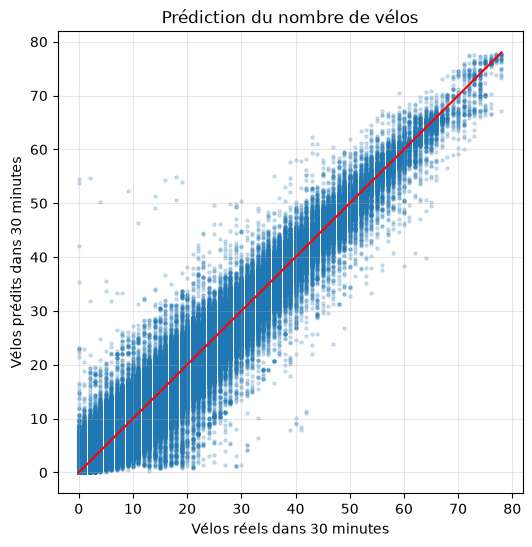

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(vrai, prediction, alpha=0.2, s=5)
plt.plot([0, vrai.max()], [0, vrai.max()], color="red")
plt.xlabel("Vélos réels dans 30 minutes")
plt.ylabel("Vélos prédits dans 30 minutes")
plt.title("Prédiction du nombre de vélos")
plt.show()

In [46]:
# On garde une ligne par station du test
resultats_stations = test[["station_id", "velos", "velos_futur"]].copy()

resultats_stations["velos_predits"] = prediction

resultats_stations["erreur"] = (
    resultats_stations["velos_predits"] - resultats_stations["velos_futur"]
)

resultats_stations["erreur_absolue"] = resultats_stations["erreur"].abs()

resultats_stations.head()

,station_id,velos,velos_futur,velos_predits,erreur,erreur_absolue
1004,1002059045,25,24,24.114667,0.114667,0.114667
1005,1002059045,25,23,23.970000,0.970000,0.970000
1006,1002059045,25,23,23.970000,0.970000,0.970000
1007,1002059045,25,24,24.150667,0.150667,0.150667
1008,1002059045,25,23,24.084667,1.084667,1.084667


### Exemples rétrospectifs avec les plus faibles prédictions

Le tableau ci-dessous trie des observations historiques du jeu de test. Ce n'est pas une liste de stations actuellement menacées : les valeurs futures y figurent seulement pour contrôler l'erreur.


In [47]:
prochaines_vides = (
    resultats_stations
    .sort_values("velos_predits")
    .drop_duplicates("station_id")
    .head(10)
)

prochaines_vides[["station_id", "velos", "velos_futur", "velos_predits"]]

,station_id,velos,velos_futur,velos_predits
961327,210403080,0,0,0.0
1682277,442739463,0,0,0.0
909393,20637435296,0,0,0.0
2366305,82381710,0,2,0.0
2217150,66491366,0,0,0.0
902746,20636823021,0,1,0.0
890605,20636368032,0,0,0.0
1181627,245187072,0,0,0.0
1483613,35380305,0,0,0.0
1583844,39202840,0,0,0.0


### Exemple rétrospectif pour une station


In [48]:
station_choisie = "213688169"

station = resultats_stations[
    resultats_stations["station_id"] == station_choisie
]

print("Nombre de prédictions :", len(station))
print("Vélos actuels en moyenne :", round(station["velos"].mean(), 1))
print("Vélos réels dans 30 min en moyenne :", round(station["velos_futur"].mean(), 1))
print("Vélos prédits dans 30 min en moyenne :", round(station["velos_predits"].mean(), 1))
print("Erreur absolue moyenne :", round(station["erreur_absolue"].mean(), 1), "vélos")

Nombre de prédictions : 430
Vélos actuels en moyenne : 15.2
Vélos réels dans 30 min en moyenne : 15.4
Vélos prédits dans 30 min en moyenne : 15.1
Erreur absolue moyenne : 1.4 vélos


In [49]:
station[["velos", "velos_futur", "velos_predits", "erreur"]].head(10)

,velos,velos_futur,velos_predits,erreur
1048486,7,7,6.730000,-0.270000
1048487,7,8,7.000000,-1.000000
1048488,8,8,8.348667,0.348667
1048489,9,10,9.162500,-0.837500
1048490,7,10,6.670000,-3.330000
1048491,7,10,6.720000,-3.280000
1048492,7,10,6.934000,-3.066000
1048493,8,11,7.991667,-3.008333
1048494,8,10,7.853500,-2.146500
1048495,10,10,12.136000,2.136000


### Stations où la régression se trompe le plus


In [50]:
erreurs_station = (
    resultats_stations
    .groupby("station_id")["erreur_absolue"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

erreurs_station

station_id
54000588      4.154121
394404659     3.846984
523900881     3.629621
49423507      3.505487
66491397      3.478428
100893610     3.323427
1056959071    3.274878
389788858     3.273010
39254792      3.168029
82405965      3.125419
Name: erreur_absolue, dtype: float64

### Erreur moyenne des dix stations les plus difficiles


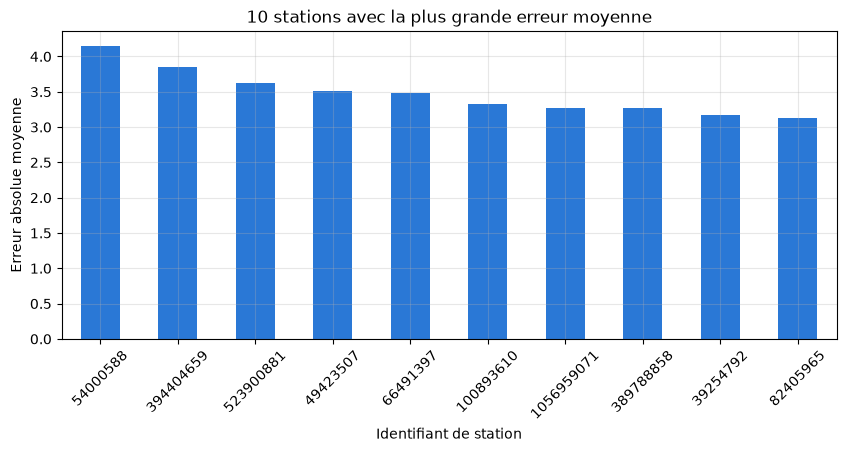

In [51]:
plt.figure(figsize=(10, 4))
erreurs_station.plot(kind="bar", color=BLEU)
plt.title("10 stations avec la plus grande erreur moyenne")
plt.xlabel("Identifiant de station")
plt.ylabel("Erreur absolue moyenne")
plt.xticks(rotation=45)
plt.show()

In [52]:
alertes = resultats_stations[resultats_stations["velos_predits"] <= 2]

print("Nombre d'alertes 'presque vide' :", len(alertes))
print("Part des observations concernées :", round(len(alertes) / len(resultats_stations) * 100, 1), "%")

alertes[["station_id", "velos", "velos_futur", "velos_predits"]].head(10)

Nombre d'alertes 'presque vide' : 70230
Part des observations concernées : 11.0 %


,station_id,velos,velos_futur,velos_predits
1189,1002059045,1,1,1.810000
1190,1002059045,1,1,1.780000
1191,1002059045,1,1,1.880000
1192,1002059045,1,1,1.210000
1193,1002059045,1,1,1.240000
1194,1002059045,1,1,1.340000
1195,1002059045,1,1,1.424667
1196,1002059045,1,2,1.424667
1197,1002059045,1,2,1.424667
1198,1002059045,1,2,1.424667


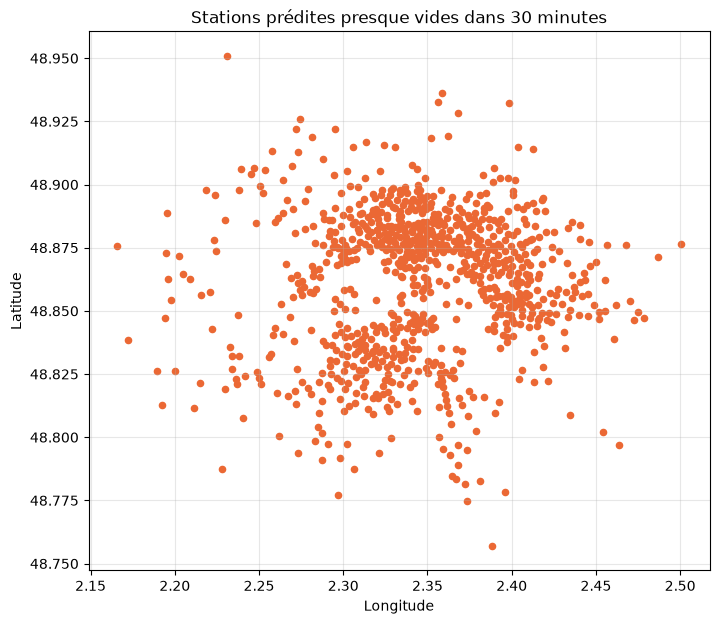

,name,velos,velos_futur,velos_predits
0,Pont Neuf - Rivoli,1,1,1.810000
1,Guynemer - Jardin du Luxembourg,0,0,1.560000
2,Bréa - Raspail,1,0,1.070000
3,Cité Vaneau,1,1,1.660000
4,Boulets - Faubourg Saint-Antoine,3,4,1.580000
5,Parmentier - Fontaine au Roi,3,3,1.840000
6,Place Pasdeloup,0,0,1.850000
7,Léon Frot - Charonne,1,1,1.293333
8,Vivaldi - Antoine-Julien Hénard,3,4,1.860000
9,Stalingrad - Rigollots,0,0,1.220000


In [53]:
carte_alertes = (
    alertes
    .drop_duplicates("station_id")
    .merge(ref[["station_id", "name", "lat", "lon"]], on="station_id", how="left")
)

plt.figure(figsize=(9, 7))
plt.scatter(carte_alertes["lon"], carte_alertes["lat"], s=20, color=ORANGE)
plt.title("Stations prédites presque vides dans 30 minutes")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect(1.5)
plt.show()

carte_alertes[["name", "velos", "velos_futur", "velos_predits"]].head(10)